In [2]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from imblearn.over_sampling import SMOTE

In [3]:
# Load the dataset
data = pd.read_csv("dataset\Disease_symptom.csv")

In [4]:
# Display the first few rows of the dataset
data.head()

,Disease,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,Outcome Variable
0,Influenza,Yes,No,Yes,Yes,19,Female,Low,Normal,Positive
1,Common Cold,No,Yes,Yes,No,25,Female,Normal,Normal,Negative
2,Eczema,No,Yes,Yes,No,25,Female,Normal,Normal,Negative
3,Asthma,Yes,Yes,No,Yes,25,Male,Normal,Normal,Positive
4,Asthma,Yes,Yes,No,Yes,25,Male,Normal,Normal,Positive


In [5]:
# Check for missing values
data.isnull().sum()

Disease                 0
Fever                   0
Cough                   0
Fatigue                 0
Difficulty Breathing    0
Age                     0
Gender                  0
Blood Pressure          0
Cholesterol Level       0
Outcome Variable        0
dtype: int64

In [37]:
data['Disease'].unique()

array([ 56,  24,  37,   6,  53,   1,   4,  32,  42,  81,  92,  31,  60,
       101, 112,  30,  48,  57,  69,  72,  98, 111,   9,  13,  15,  23,
        52,  70,  73, 113,  77,  84,   7,  21,  39,  51,  74,  90,  93,
        22,  25,  61,  65, 100,  58,  75,  59,   0,  11,  28,  43,  91,
        16,  26,  35,  41,  46,  54,  64, 108,  62,  55,   8,  27,  50,
        68,  79, 109, 115,  14,  83,  95,  97, 104,   3,  18,  38,  96,
        99,  34,  36,  63,  80,  85,   5,  40,  45,  66,  82,  47,  87,
       102, 110,  12,  67,  76,  86,  19,  49,  88, 105,  10,  78, 107,
         2,  20,  29,  33,  71,  17,  89,  94,  44, 103, 106, 114])

In [6]:
data.duplicated().sum()

49

In [7]:
data = data.drop_duplicates()

In [8]:
# Basic statistics of the dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 300 entries, 0 to 347
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Disease               300 non-null    object
 1   Fever                 300 non-null    object
 2   Cough                 300 non-null    object
 3   Fatigue               300 non-null    object
 4   Difficulty Breathing  300 non-null    object
 5   Age                   300 non-null    int64 
 6   Gender                300 non-null    object
 7   Blood Pressure        300 non-null    object
 8   Cholesterol Level     300 non-null    object
 9   Outcome Variable      300 non-null    object
dtypes: int64(1), object(9)
memory usage: 25.8+ KB


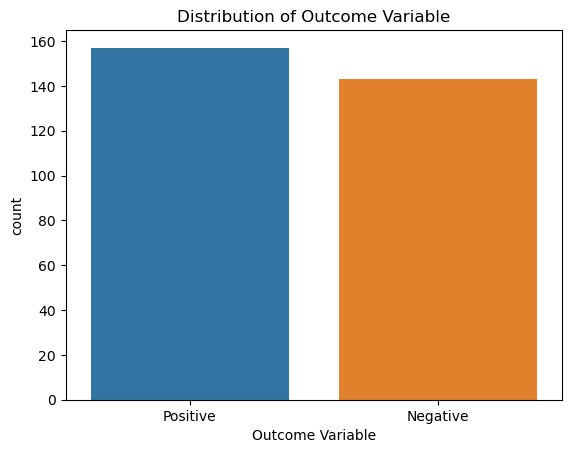

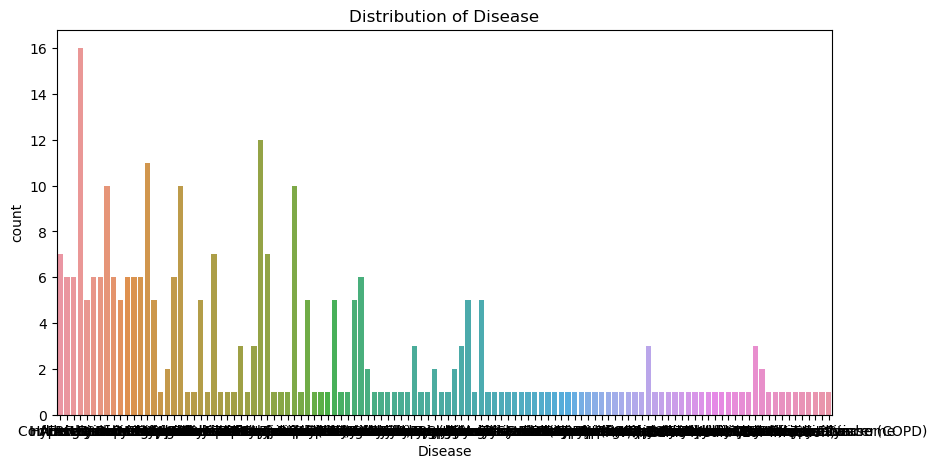

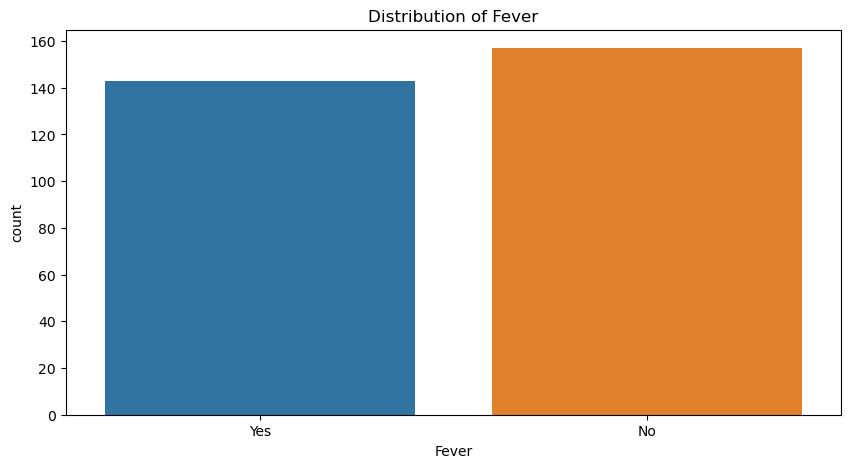

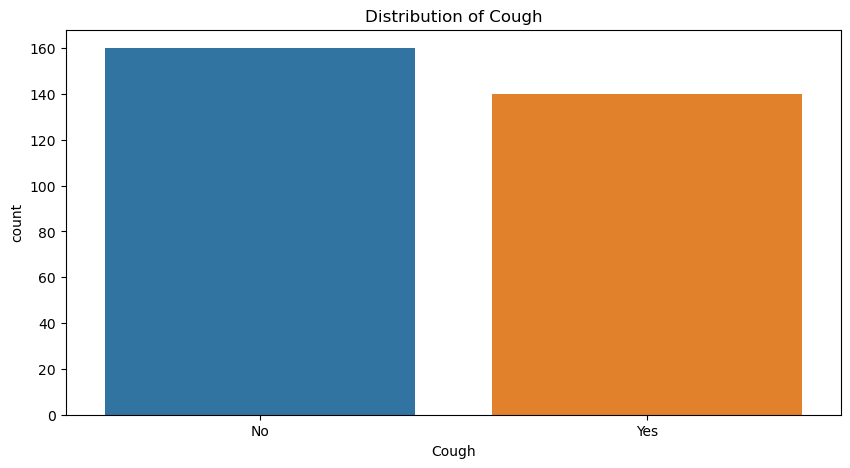

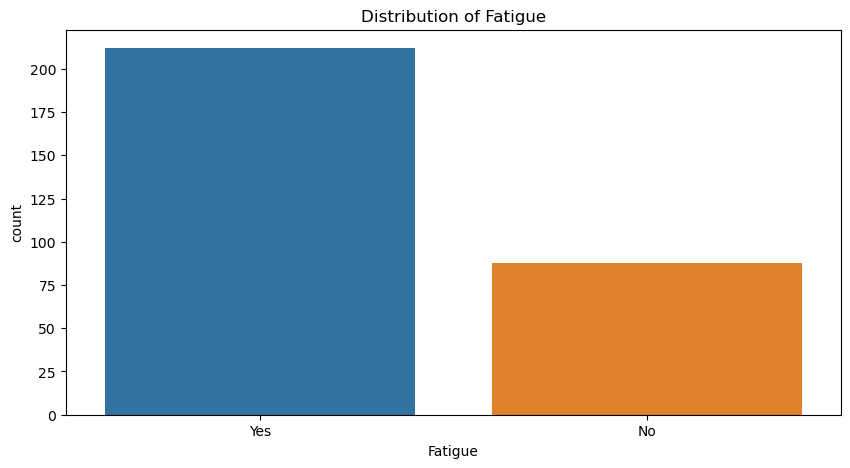

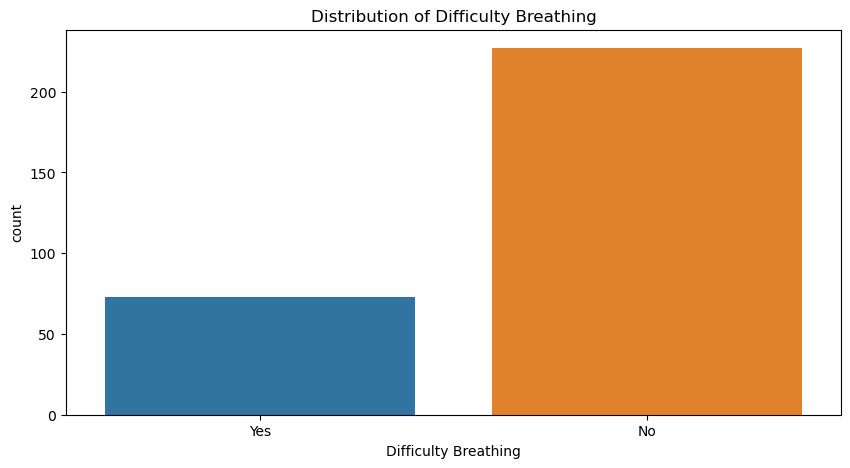

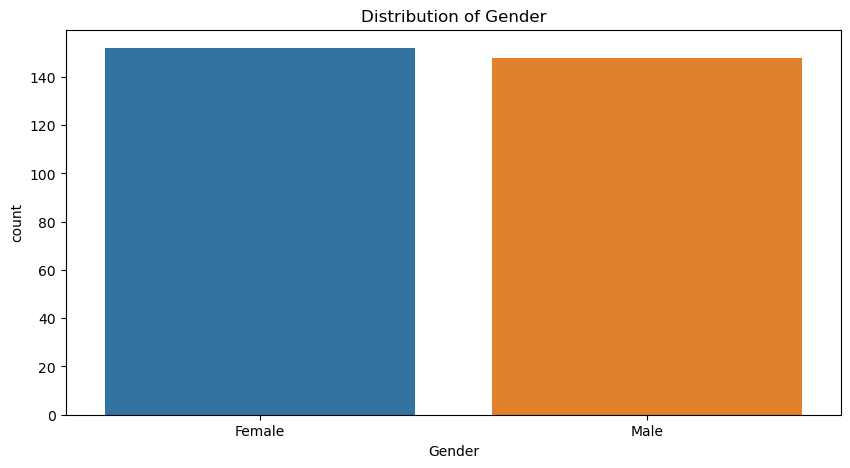

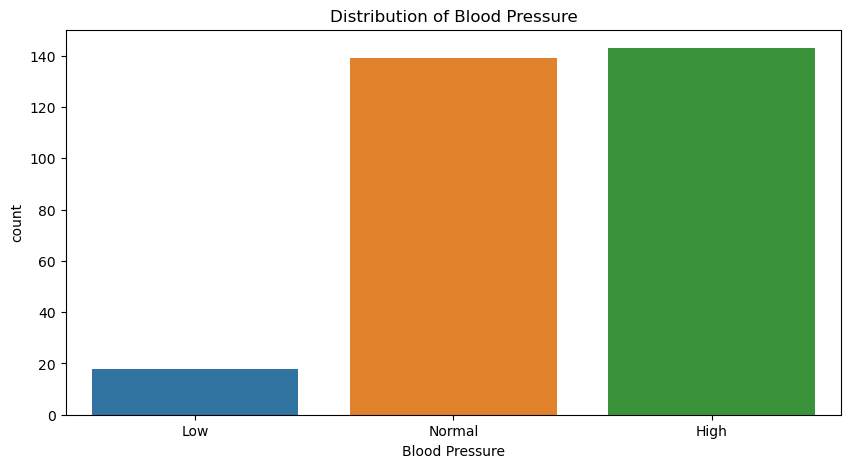

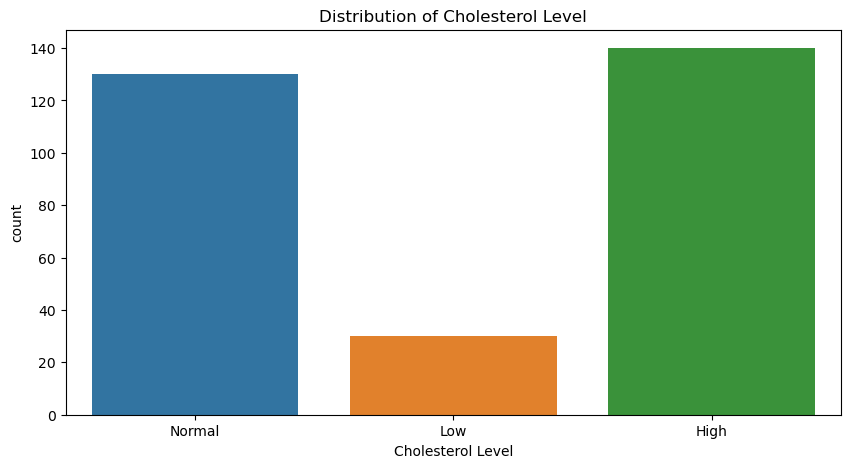

In [9]:
# Visualize the distribution of the target variable
sns.countplot(x='Outcome Variable', data=data)
plt.title('Distribution of Outcome Variable')
plt.show()

# Visualize the distribution of symptoms and other categorical variables
categorical_columns = ['Disease', 'Fever', 'Cough', 'Fatigue', 'Difficulty Breathing', 'Gender', 'Blood Pressure', 'Cholesterol Level']

for column in categorical_columns:
    plt.figure(figsize=(10, 5))
    sns.countplot(x=column, data=data)
    plt.title(f'Distribution of {column}')
    plt.show()

In [10]:
fig = px.histogram(data, 
             x = 'Age',  
             title='Age-Disease Distribution',
             color= 'Disease'
                  )
fig.update_layout(bargap=0.2)

fig.show()

In [11]:
# Initialize the label encoder
le_disease = LabelEncoder()
le_fever = LabelEncoder()
le_cough = LabelEncoder()
le_fatigue = LabelEncoder()
le_difficulty_breathing = LabelEncoder()
le_gender = LabelEncoder()
le_blood_pressure = LabelEncoder()
le_cholesterol_level = LabelEncoder()

# Fit and transform the categorical columns
data['Disease'] = le_disease.fit_transform(data['Disease'])
data['Fever'] = le_fever.fit_transform(data['Fever'])
data['Cough'] = le_cough.fit_transform(data['Cough'])
data['Fatigue'] = le_fatigue.fit_transform(data['Fatigue'])
data['Difficulty Breathing'] = le_difficulty_breathing.fit_transform(data['Difficulty Breathing'])
data['Gender'] = le_gender.fit_transform(data['Gender'])
data['Blood Pressure'] = le_blood_pressure.fit_transform(data['Blood Pressure'])
data['Cholesterol Level'] = le_cholesterol_level.fit_transform(data['Cholesterol Level'])
data['Outcome Variable'] = LabelEncoder().fit_transform(data['Outcome Variable'])

# Creating mappings for each column
disease_mapping = dict(zip(le_disease.classes_, le_disease.transform(le_disease.classes_)))
fever_mapping = dict(zip(le_fever.classes_, le_fever.transform(le_fever.classes_)))
cough_mapping = dict(zip(le_cough.classes_, le_cough.transform(le_cough.classes_)))
fatigue_mapping = dict(zip(le_fatigue.classes_, le_fatigue.transform(le_fatigue.classes_)))
difficulty_breathing_mapping = dict(zip(le_difficulty_breathing.classes_, le_difficulty_breathing.transform(le_difficulty_breathing.classes_)))
gender_mapping = dict(zip(le_gender.classes_, le_gender.transform(le_gender.classes_)))
blood_pressure_mapping = dict(zip(le_blood_pressure.classes_, le_blood_pressure.transform(le_blood_pressure.classes_)))
cholesterol_level_mapping = dict(zip(le_cholesterol_level.classes_, le_cholesterol_level.transform(le_cholesterol_level.classes_)))
outcome_mapping = dict(zip(['Negative', 'Positive'], [0, 1]))

# Print mappings
disease_mapping, fever_mapping, cough_mapping, fatigue_mapping, difficulty_breathing_mapping, gender_mapping, blood_pressure_mapping, cholesterol_level_mapping, outcome_mapping


({'Acne': 0,
  'Allergic Rhinitis': 1,
  "Alzheimer's Disease": 2,
  'Anemia': 3,
  'Anxiety Disorders': 4,
  'Appendicitis': 5,
  'Asthma': 6,
  'Atherosclerosis': 7,
  'Autism Spectrum Disorder (ASD)': 8,
  'Bipolar Disorder': 9,
  'Bladder Cancer': 10,
  'Brain Tumor': 11,
  'Breast Cancer': 12,
  'Bronchitis': 13,
  'Cataracts': 14,
  'Cerebral Palsy': 15,
  'Chickenpox': 16,
  'Cholecystitis': 17,
  'Cholera': 18,
  'Chronic Kidney Disease': 19,
  'Chronic Obstructive Pulmonary Disease (COPD)': 20,
  'Chronic Obstructive Pulmonary...': 21,
  'Cirrhosis': 22,
  'Colorectal Cancer': 23,
  'Common Cold': 24,
  'Conjunctivitis (Pink Eye)': 25,
  'Coronary Artery Disease': 26,
  "Crohn's Disease": 27,
  'Cystic Fibrosis': 28,
  'Dementia': 29,
  'Dengue Fever': 30,
  'Depression': 31,
  'Diabetes': 32,
  'Diverticulitis': 33,
  'Down Syndrome': 34,
  'Eating Disorders (Anorexia,...': 35,
  'Ebola Virus': 36,
  'Eczema': 37,
  'Endometriosis': 38,
  'Epilepsy': 39,
  'Esophageal Cancer'

In [13]:
# Define the desired sample size
desired_sample_size = 1000

# Use the sample method to increase the dataset size with replacement
data_sampled = data.sample(n=desired_sample_size, replace=True, random_state=42)

# Verify the new sample size
new_sample_size = len(data_sampled)

# Output the new sample size
new_sample_size

1000

In [23]:
data_sampled

,Disease,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,Outcome Variable
114,13,0,1,0,1,40,0,2,2,0
310,113,1,0,1,0,65,1,0,2,0
118,75,0,0,1,0,40,1,0,2,0
81,53,1,1,1,0,35,1,0,0,1
214,38,1,0,0,0,50,1,0,2,0
...,...,...,...,...,...,...,...,...,...,...
243,13,0,0,1,1,55,1,0,0,0
238,111,0,1,1,0,50,0,2,0,1
36,6,1,1,1,1,30,0,2,2,1
177,115,0,1,1,0,45,0,0,0,0


In [24]:
# Separate features and target
X = data_sampled.drop(columns=['Outcome Variable'])
y = data_sampled['Outcome Variable']

In [25]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.2, random_state=42)

# Check the shape of the splits
(X_train.shape, X_val.shape, X_test.shape)

((800, 9), (160, 9), (40, 9))

Logistic Regression: Accuracy = 0.60625
Random Forest: Accuracy = 0.9625
SVM: Accuracy = 0.56875
KNN: Accuracy = 0.86875
Decision Tree: Accuracy = 0.95625


e:\AI\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1765: FutureWarning:

unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.



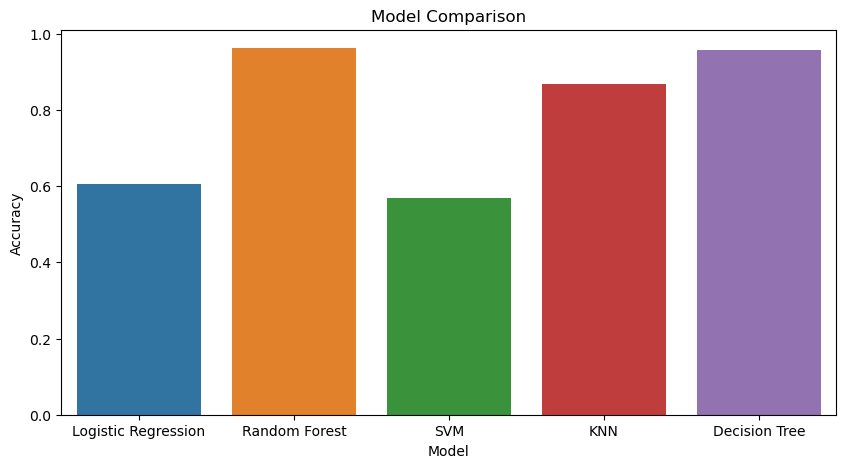

In [26]:
# List of models to evaluate
models = {
    'Logistic Regression': LogisticRegression(max_iter=10000),
    'Random Forest': RandomForestClassifier(),
    'SVM': SVC(probability=True),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier()
}

# Function to train and evaluate models
def evaluate_models(models, X_train, y_train, X_val, y_val):
    results = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        acc = accuracy_score(y_val, y_pred)
        results[name] = acc
        print(f'{name}: Accuracy = {acc}')
    return results

# Evaluate models
results = evaluate_models(models, X_train, y_train, X_val, y_val)

# Plot the results
plt.figure(figsize=(10, 5))
sns.barplot(x=list(results.keys()), y=list(results.values()))
plt.title('Model Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.show()

Accuracy: 1.0
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        28

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

Confusion Matrix:
 [[12  0]
 [ 0 28]]


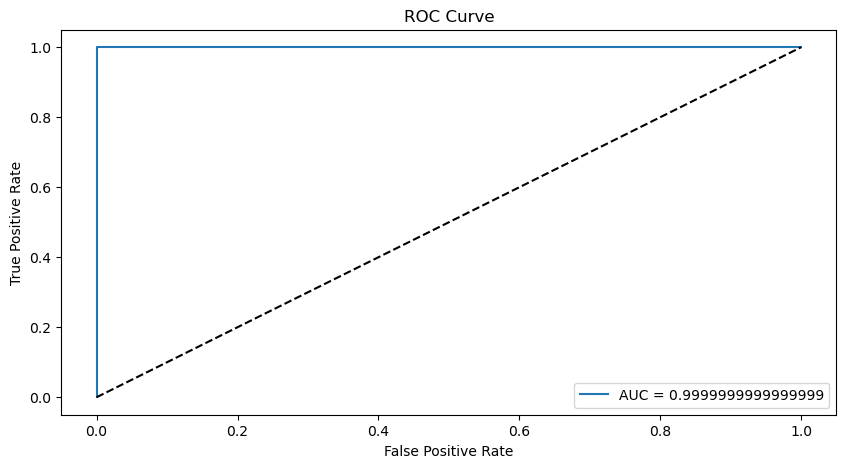

In [27]:
# Select the best model based on validation accuracy
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]

# Train the best model on the entire training set
best_model.fit(X_train, y_train)

# Predict on the test set
y_test_pred = best_model.predict(X_test)

# Evaluate the model
print(f'Accuracy: {accuracy_score(y_test, y_test_pred)}')
print(f'Classification Report:\n {classification_report(y_test, y_test_pred)}')
print(f'Confusion Matrix:\n {confusion_matrix(y_test, y_test_pred)}')

# ROC curve and AUC
y_test_prob = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(10, 5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [29]:
def preprocess_input(input_data):
    # Convert actual values to encoded values
    input_data['Disease'] = disease_mapping[input_data['Disease']]
    input_data['Fever'] = fever_mapping[input_data['Fever']]
    input_data['Cough'] = cough_mapping[input_data['Cough']]
    input_data['Fatigue'] = fatigue_mapping[input_data['Fatigue']]
    input_data['Difficulty Breathing'] = difficulty_breathing_mapping[input_data['Difficulty Breathing']]
    input_data['Gender'] = gender_mapping[input_data['Gender']]
    input_data['Blood Pressure'] = blood_pressure_mapping[input_data['Blood Pressure']]
    input_data['Cholesterol Level'] = cholesterol_level_mapping[input_data['Cholesterol Level']]
    
    return pd.DataFrame([input_data])

In [30]:
def make_prediction(input_data):
    # Preprocess the input data
    preprocessed_data = preprocess_input(input_data)
    
    # Make prediction
    prediction = best_model.predict(preprocessed_data)
    
    # Map the prediction to the actual outcome
    outcome_mapping = {0: 'Negative', 1: 'Positive'}
    
    return outcome_mapping[prediction[0]]

In [33]:
# Example input data
input_data = {
    'Disease': 'Asthma',
    'Fever': 'Yes',
    'Cough': 'No',
    'Fatigue': 'Yes',
    'Difficulty Breathing': 'No',
    'Age':30,
    'Gender': 'Male',
    'Blood Pressure': 'Normal',
    'Cholesterol Level': 'High'
}
# Make a prediction
result = make_prediction(input_data)
print(f'The predicted outcome for the input data is: {result}')


The predicted outcome for the input data is: Positive


In [48]:
from flask import Flask, request, jsonify
import joblib
from flask_cors import CORS
import numpy as np

app = Flask(__name__)
CORS(app)
@app.route('/check', methods=['POST'])
def predict():
    input_data = request.json
    result = make_prediction(input_data)
    return jsonify({'prediction': result})

if __name__ == '__main__':
    app.run(debug=False, host='0.0.0.0', port=5000)

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://192.168.1.6:5000
Press CTRL+C to quit
127.0.0.1 - - [17/Jun/2024 02:29:02] "POST /check HTTP/1.1" 200 -
127.0.0.1 - - [17/Jun/2024 02:30:35] "POST /check HTTP/1.1" 200 -
127.0.0.1 - - [17/Jun/2024 02:31:33] "POST /check HTTP/1.1" 200 -


In [28]:
disease_mapping

{'Acne': 0,
 'Allergic Rhinitis': 1,
 "Alzheimer's Disease": 2,
 'Anemia': 3,
 'Anxiety Disorders': 4,
 'Appendicitis': 5,
 'Asthma': 6,
 'Atherosclerosis': 7,
 'Autism Spectrum Disorder (ASD)': 8,
 'Bipolar Disorder': 9,
 'Bladder Cancer': 10,
 'Brain Tumor': 11,
 'Breast Cancer': 12,
 'Bronchitis': 13,
 'Cataracts': 14,
 'Cerebral Palsy': 15,
 'Chickenpox': 16,
 'Cholecystitis': 17,
 'Cholera': 18,
 'Chronic Kidney Disease': 19,
 'Chronic Obstructive Pulmonary Disease (COPD)': 20,
 'Chronic Obstructive Pulmonary...': 21,
 'Cirrhosis': 22,
 'Colorectal Cancer': 23,
 'Common Cold': 24,
 'Conjunctivitis (Pink Eye)': 25,
 'Coronary Artery Disease': 26,
 "Crohn's Disease": 27,
 'Cystic Fibrosis': 28,
 'Dementia': 29,
 'Dengue Fever': 30,
 'Depression': 31,
 'Diabetes': 32,
 'Diverticulitis': 33,
 'Down Syndrome': 34,
 'Eating Disorders (Anorexia,...': 35,
 'Ebola Virus': 36,
 'Eczema': 37,
 'Endometriosis': 38,
 'Epilepsy': 39,
 'Esophageal Cancer': 40,
 'Fibromyalgia': 41,
 'Gastroenteri

In [38]:
import sklearn
print(sklearn.__version__)
print(joblib.__version__)

1.4.1.post1
1.3.2


In [39]:
import joblib

# Serialize the trained model
joblib.dump(best_model, 'disease_check.pkl')
#joblib.dump(DT_model, 'DT_model.pkl')

['disease_check.pkl']

In [16]:
# Output the mappings and the new sample size
mappings = {
    'Disease': dict(zip(le_disease.classes_, le_disease.transform(le_disease.classes_))),
    'Fever': dict(zip(le_fever.classes_, le_fever.transform(le_fever.classes_))),
    'Cough': dict(zip(le_cough.classes_, le_cough.transform(le_cough.classes_))),
    'Fatigue': dict(zip(le_fatigue.classes_, le_fatigue.transform(le_fatigue.classes_))),
    'Difficulty Breathing': dict(zip(le_difficulty_breathing.classes_, le_difficulty_breathing.transform(le_difficulty_breathing.classes_))),
    'Gender': dict(zip(le_gender.classes_, le_gender.transform(le_gender.classes_))),
    'Blood Pressure': dict(zip(le_blood_pressure.classes_, le_blood_pressure.transform(le_blood_pressure.classes_))),
    'Cholesterol Level': dict(zip(le_cholesterol_level.classes_, le_cholesterol_level.transform(le_cholesterol_level.classes_))),
    'Outcome Variable': {'Negative': 0, 'Positive': 1}
}

mappings['Disease']

{'Acne': 0,
 'Allergic Rhinitis': 1,
 "Alzheimer's Disease": 2,
 'Anemia': 3,
 'Anxiety Disorders': 4,
 'Appendicitis': 5,
 'Asthma': 6,
 'Atherosclerosis': 7,
 'Autism Spectrum Disorder (ASD)': 8,
 'Bipolar Disorder': 9,
 'Bladder Cancer': 10,
 'Brain Tumor': 11,
 'Breast Cancer': 12,
 'Bronchitis': 13,
 'Cataracts': 14,
 'Cerebral Palsy': 15,
 'Chickenpox': 16,
 'Cholecystitis': 17,
 'Cholera': 18,
 'Chronic Kidney Disease': 19,
 'Chronic Obstructive Pulmonary Disease (COPD)': 20,
 'Chronic Obstructive Pulmonary...': 21,
 'Cirrhosis': 22,
 'Colorectal Cancer': 23,
 'Common Cold': 24,
 'Conjunctivitis (Pink Eye)': 25,
 'Coronary Artery Disease': 26,
 "Crohn's Disease": 27,
 'Cystic Fibrosis': 28,
 'Dementia': 29,
 'Dengue Fever': 30,
 'Depression': 31,
 'Diabetes': 32,
 'Diverticulitis': 33,
 'Down Syndrome': 34,
 'Eating Disorders (Anorexia,...': 35,
 'Ebola Virus': 36,
 'Eczema': 37,
 'Endometriosis': 38,
 'Epilepsy': 39,
 'Esophageal Cancer': 40,
 'Fibromyalgia': 41,
 'Gastroenteri

In [52]:
for i in mappings.keys:
    print(I)

TypeError: 'builtin_function_or_method' object is not iterable

In [50]:
%pip install gunicorn

   ---------------------------------------- 0.0/84.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/84.4 kB ? eta -:--:--
   ---- ----------------------------------- 10.2/84.4 kB ? eta -:--:--
   ---- ----------------------------------- 10.2/84.4 kB ? eta -:--:--
   ---- ----------------------------------- 10.2/84.4 kB ? eta -:--:--
   ---- ----------------------------------- 10.2/84.4 kB ? eta -:--:--
   ------------------- -------------------- 41.0/84.4 kB 245.8 kB/s eta 0:00:01
   ----------------------------- ---------- 61.4/84.4 kB 297.7 kB/s eta 0:00:01
   ---------------------------------------- 84.4/84.4 kB 365.5 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [40]:
df = pd.read_csv('dataset\Disease_symptom.csv')

In [47]:
df['Disease'].unique()

array(['Influenza', 'Common Cold', 'Eczema', 'Asthma', 'Hyperthyroidism',
       'Allergic Rhinitis', 'Anxiety Disorders', 'Diabetes',
       'Gastroenteritis', 'Pancreatitis', 'Rheumatoid Arthritis',
       'Depression', 'Liver Cancer', 'Stroke', 'Urinary Tract Infection',
       'Dengue Fever', 'Hepatitis', 'Kidney Cancer', 'Migraine',
       'Muscular Dystrophy', 'Sinusitis', 'Ulcerative Colitis',
       'Bipolar Disorder', 'Bronchitis', 'Cerebral Palsy',
       'Colorectal Cancer', 'Hypertensive Heart Disease',
       'Multiple Sclerosis', 'Myocardial Infarction (Heart...',
       'Urinary Tract Infection (UTI)', 'Osteoporosis', 'Pneumonia',
       'Atherosclerosis', 'Chronic Obstructive Pulmonary...', 'Epilepsy',
       'Hypertension', 'Obsessive-Compulsive Disorde...', 'Psoriasis',
       'Rubella', 'Cirrhosis', 'Conjunctivitis (Pink Eye)',
       'Liver Disease', 'Malaria', 'Spina Bifida', 'Kidney Disease',
       'Osteoarthritis', 'Klinefelter Syndrome', 'Acne', 'Brain Tumor',
